# 04 · Explainability, fairness, privacy and monitoring
**Responsible AI and MLOps**

> **At a glance**
> * **Explainable:** SHAP shows the forecast runs on each store's own history (~78%) and store context (~11%);
>   demographics add ~1%.
> * **Fair:** the model beats today's rule for **every** group of counties and store types, but rural and border
>   counties still carry ~+7% bias (half the status quo's) and brand-new stores are under-forecast.
> * **No sensitive attribute needed:** % Hispanic was removed from the model by a rule set in advance.
> * **Monitored:** drift (PSI), monthly error, schema changes and an explicit retraining rule.

The four questions: *Can a planner see why the model says what it says? Does it serve every kind of county equally
well? Does it rely on sensitive data it does not need? Will we notice when it stops working?*

**Contents**
1. Global explanation (SHAP)
2. Local explanation: one forecast
3. Fairness audit
4. The sensitive-attribute decision
5. Privacy, ethics and governance
6. Monitoring: drift and retraining
7. The MLOps stack

In [1]:
import sys, json, sqlite3, subprocess
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
from abd_demand import config as C, plotting as P, forecast as Fc

P.use_style()
pd.set_option("display.width", 170)
pd.set_option("display.float_format", "{:,.3f}".format)

TABLES = C.ROOT / "reports" / "tables"
model, meta = Fc.load_model(C.MODELS / "xgb_tweedie_final.json")
FEATURES = meta["features"]
test = Fc.split(Fc.load_panel(), "test")                                   # the test months, as model inputs
predictions = pd.read_parquet(TABLES / "test_predictions.parquet")

## 1. Global explanation: what drives the forecast?
> **Technique card — SHAP (SHapley Additive exPlanations).** For each forecast, SHAP splits the prediction into one
> contribution per feature, so that *base value + all contributions = prediction*. The idea comes from game theory
> (Shapley values): each feature gets its fair share of the credit, averaged over every order in which features
> could be added. For tree models (XGBoost) the values are computed **exactly** (TreeSHAP), not approximated.
> Here contributions are on the log scale: exp(SHAP) is a multiplicative effect on the forecast.
>
> *Global importance* = the average size of a feature's contribution across many forecasts.

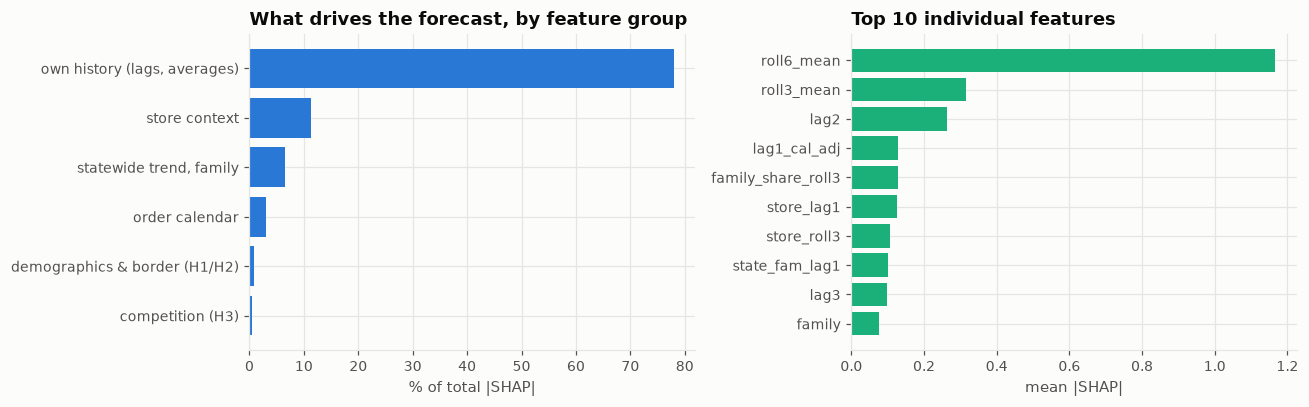

In [2]:
sample = test.sample(4000, random_state=C.SEED)
contributions = model.get_booster().predict(xgb.DMatrix(sample[FEATURES], enable_categorical=True), pred_contribs=True)
shap_values = contributions[:, :-1]                       # last column is the base value
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
importance.to_csv(TABLES / "shap_importance.csv")

groups = {
    "own history (lags, averages)": ["lag1", "lag2", "lag3", "lag6", "lag12", "roll3_mean", "roll6_mean", "roll6_std",
                                     "active_share6", "lines_lag1", "lag1_cal_adj", "lag12_cal_adj", "family_share_roll3"],
    "store context":                ["store_lag1", "store_roll3", "store_lag12", "store_age_months", "store_type"],
    "order calendar":               ["order_days", "cal_ratio_lag1", "cal_ratio_lag12", "business_days", "month_of_year"],
    "competition (H3)":             ["city_active_stores_lag1", "city_new_entrants_last3"],
    "demographics & border (H1/H2)": ["log_population", "cty_median_household_income", "cty_pct_hispanic",
                                      "cty_pct_bachelors_or_higher", "cty_median_age", "cty_poverty_rate",
                                      "cty_pct_age_21_34", "geo_pop_density", "geo_borders_mo", "geo_border_tax_gap",
                                      "geo_log_hub_ratio"],
    "statewide trend, family":      ["state_fam_lag1", "state_fam_yoy", "family"],
}
group_share = pd.Series({g: importance.reindex(f).dropna().sum() for g, f in groups.items()}) / importance.sum()
group_share = group_share.sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].barh(group_share.index, 100 * group_share.values, color=P.BLUE)
axes[0].set_xlabel("% of total |SHAP|"); axes[0].set_title("What drives the forecast, by feature group")
top = importance.head(10).sort_values()
axes[1].barh(top.index, top.values, color=P.AQUA)
axes[1].set_xlabel("mean |SHAP|"); axes[1].set_title("Top 10 individual features")
plt.tight_layout(); plt.show()

**The beeswarm plot** shows the same thing in more detail: one dot per forecast; position = how much that feature
pushed the forecast up (right) or down (left); colour = whether the feature's value was high (red) or low (blue).

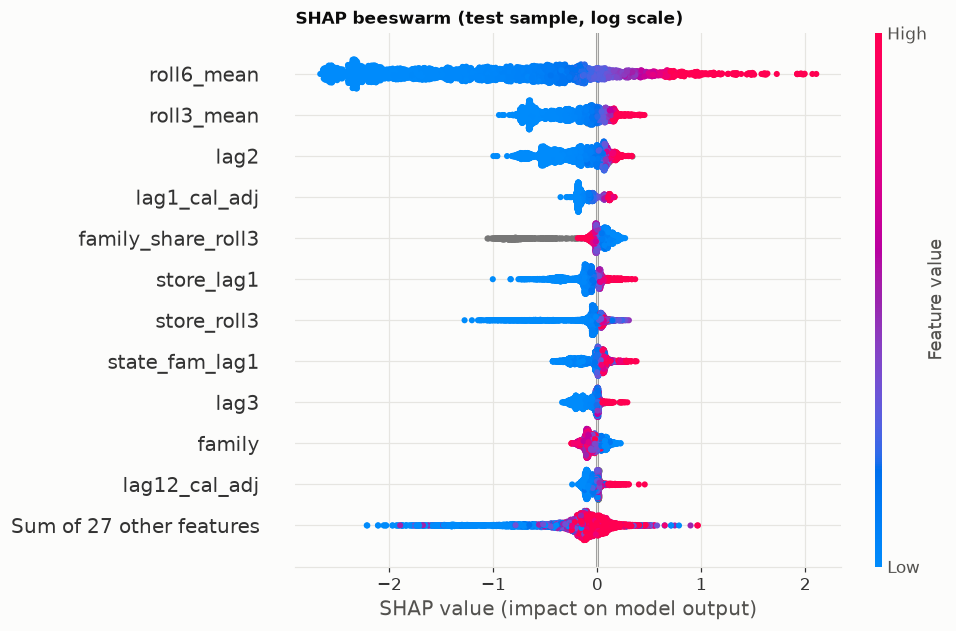

In [3]:
data_numeric = sample[FEATURES].copy()
for c in ["family", "store_type"]:
    data_numeric[c] = data_numeric[c].cat.codes
explanation = shap.Explanation(values=shap_values, base_values=contributions[:, -1],
                               data=data_numeric.values, feature_names=FEATURES)
plt.figure()
shap.plots.beeswarm(explanation, max_display=12, show=False)
plt.title("SHAP beeswarm (test sample, log scale)", loc="left", fontsize=11)
P.save(plt.gcf(), "shap_beeswarm"); plt.show()

**Reading it.** The forecast is driven by each series' **own history** and **store context**, then the statewide
trend and the **order calendar**. County demographics and the border flags add ~1% once a store's history is known.
**Implication.** The H1/H2 effects explain why *levels* differ between counties, and those levels are already inside a
store's own lags. Demographics matter for planning norms and for new stores, not for next month's forecast of an existing store.

## 2. Local explanation: one forecast a planner might question
The same SHAP split, for a single forecast: the largest store-family forecast for November 2026.

In [4]:
november = pd.read_parquet(C.PROCESSED / "forecast_2026_11.parquet")
for c, levels in Fc.CATEGORY_LEVELS.items():
    november[c] = pd.Categorical(november[c].astype(str), categories=levels)
row = november.sort_values("forecast_liters", ascending=False).iloc[[0]]
store_names = pd.read_parquet(C.STORE_DIM).set_index("store_no").store_name

local = model.get_booster().predict(xgb.DMatrix(row[FEATURES], enable_categorical=True), pred_contribs=True)[0]
local = pd.Series(local[:-1], index=FEATURES)
top8 = local.reindex(local.abs().sort_values(ascending=False).index[:8])

print(f"{store_names[row.store_no.iat[0]]} – {row.family.iat[0]}, November 2026")
print(f"forecast {row.forecast_liters.iat[0]:,.0f} L = {meta['weight']} x XGBoost {row.p_xgb.iat[0]:,.0f} L "
      f"+ {1 - meta['weight']:.2f} x last year (day-adjusted) {row.p_anchor.iat[0]:,.0f} L")
def readable(v):
    return f"{v:,.0f}" if isinstance(v, (int, float, np.number)) and abs(v) >= 100 else (f"{v:.2f}" if isinstance(v, (float, np.floating)) else str(v))
pd.DataFrame({"feature value": [readable(v) for v in row[top8.index].iloc[0]],
              "effect on the XGBoost forecast": (np.exp(top8) - 1).map("{:+.0%}".format).values}, index=top8.index)

CENTRAL CITY 2 – vodka, November 2026
forecast 15,258 L = 0.55 x XGBoost 16,053 L + 0.45 x last year (day-adjusted) 14,286 L


,feature value,effect on the XGBoost forecast
roll6_mean,"16,264",+841%
roll3_mean,"14,989",+61%
lag2,"14,081",+46%
lag3,"13,836",+38%
store_lag1,"52,657",+37%
lag1_cal_adj,"17,035",+20%
lag12_cal_adj,"14,286",+18%
family,vodka,+16%


The API returns this explanation with every store forecast (`/forecast/store/{store_no}`). A planner can see, for
example, "last month's volume and the number of order days push this up", and can overrule it with a logged reason.

## 3. Fairness audit: does the forecast serve every kind of county equally?
> **Technique card — error-parity audit.** Split the test results by group (rural/urban, income, ethnicity, border,
> store type, store age) and compare error (WAPE) and bias for each. The harms to look for:
> **systematic under-forecasting** for a group (stock-outs, worse service) or **over-forecasting** (dead stock).
> We compare against the status quo too: a fair model should not make any group *worse off* than today.

In [5]:
county_profile = pd.read_parquet(C.COUNTY_PROFILE).set_index("county_fips_code")
predictions["urbanicity"] = predictions.county_fips_code.map(pd.qcut(county_profile.cty_total_population, 3, labels=["rural", "mid-size", "urban"]))
predictions["hispanic"] = predictions.county_fips_code.map(pd.qcut(county_profile.cty_pct_hispanic, 3, labels=["low", "mid", "high"]))
predictions["income"] = predictions.county_fips_code.map(pd.qcut(county_profile.cty_median_household_income, 3, labels=["low", "mid", "high"]))
predictions["mo_border"] = np.where(predictions.geo_borders_mo == 1, "Missouri border", "other")
predictions["store_age"] = np.where(predictions.store_age_months < 6, "new (<6 months)", "established")

def audit(dimension):
    rows = []
    for group, d in predictions.groupby(dimension, observed=True):
        cells = d.groupby(["county_fips_code", "family", "month"], observed=True)[["y", "p_final", "p_seasonal_naive_last_year"]].sum()
        rows.append({"dimension": dimension, "group": group, "share of liters": d.y.sum() / predictions.y.sum(),
                     "WAPE final": Fc.wape(cells.y, cells.p_final), "bias final": Fc.bias(cells.y, cells.p_final),
                     "WAPE status quo": Fc.wape(cells.y, cells.p_seasonal_naive_last_year),
                     "bias status quo": Fc.bias(cells.y, cells.p_seasonal_naive_last_year)})
    return pd.DataFrame(rows)

fairness = pd.concat([audit(d) for d in ["urbanicity", "hispanic", "income", "mo_border", "store_type", "store_age"]], ignore_index=True)
fairness["better than today"] = fairness["WAPE final"] < fairness["WAPE status quo"]
fairness.to_csv(TABLES / "fairness_audit.csv", index=False)
fairness

,dimension,group,share of liters,WAPE final,bias final,WAPE status quo,bias status quo,better than today
0,urbanicity,rural,0.047,0.271,0.068,0.342,0.120,True
1,urbanicity,mid-size,0.120,0.224,0.069,0.284,0.123,True
2,urbanicity,urban,0.834,0.118,0.010,0.148,0.054,True
3,hispanic,low,0.103,0.199,0.066,0.251,0.115,True
4,hispanic,mid,0.328,0.146,0.004,0.180,0.053,True
5,hispanic,high,0.570,0.122,0.021,0.155,0.064,True
6,income,low,0.176,0.173,0.020,0.210,0.061,True
7,income,mid,0.198,0.189,0.036,0.234,0.078,True
8,income,high,0.627,0.112,0.015,0.144,0.063,True
9,mo_border,Missouri border,0.019,0.224,0.073,0.301,0.164,True


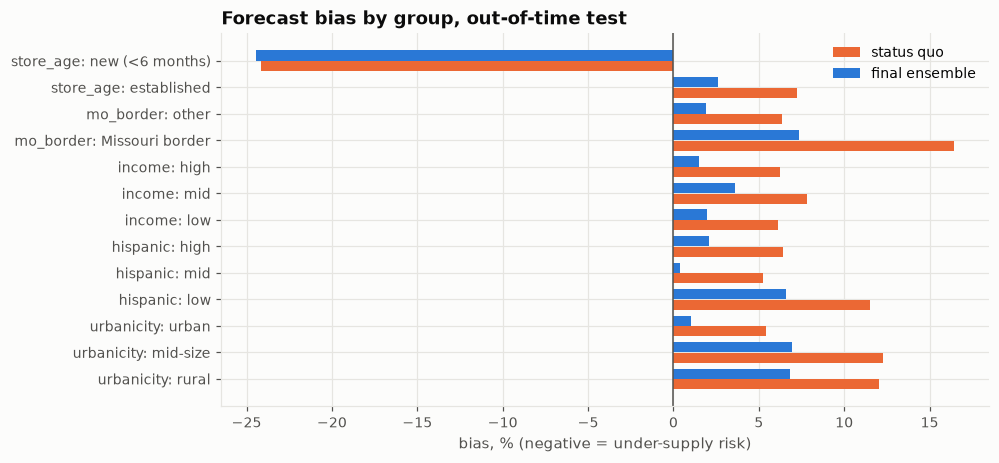

In [6]:
shown = fairness[fairness.dimension.isin(["urbanicity", "hispanic", "income", "mo_border", "store_age"])].copy()
shown["label"] = shown.dimension + ": " + shown.group.astype(str)
y = np.arange(len(shown))
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(y - 0.2, 100 * shown["bias status quo"], 0.38, color=P.ORANGE, label="status quo")
ax.barh(y + 0.2, 100 * shown["bias final"], 0.38, color=P.BLUE, label="final ensemble")
ax.axvline(0, color=P.INK2, lw=1)
ax.set_yticks(y, shown.label); ax.set_xlabel("bias, % (negative = under-supply risk)")
ax.set_title("Forecast bias by group, out-of-time test"); ax.legend()
P.save(fig, "fairness_bias"); plt.show()

**Findings.**
* The final model is **better than the status quo in every group**: no group is traded off for the average.
* **Error is not equal.** Rural counties have higher WAPE than urban ones (small volumes are noisier), and the model
  **over-forecasts rural and Missouri-border counties by ~7%**, against ~1% for urban counties: an overstock risk, and half
  the status quo's bias. Mitigation: a group-level bias correction learned on validation, and the monthly audit.
* **New stores are under-forecast by ~24%**: a stock-out risk, shared with the status quo (no history to learn from).
  Mitigation: plan new stores from similar stores for their first months (notebook 05, H20).

## 4. Do we need the sensitive attribute?
% Hispanic was useful for *understanding* demand (H2). Using an ethnicity variable inside an operational model needs a
justification, so the rule was **set in advance**: keep it only if it improves validation county WAPE by more than 1%.

In [7]:
decision = meta["sensitive_feature_decision"]
print(f"validation county WAPE with % Hispanic {decision['valid_wape_with']:.4f}, without {decision['valid_wape_without']:.4f}")
print(f"-> dropped from the production model: {meta['dropped_sensitive']}")
comparison = pd.read_csv(TABLES / "model_comparison.csv")
comparison[comparison.kind == "ablation"][["model", "wape_county", "wape_state", "wape_store", "bias"]]

validation county WAPE with % Hispanic 0.1427, without 0.1434
-> dropped from the production model: ['cty_pct_hispanic']


,model,wape_county,wape_state,wape_store,bias
23,ablation: all_features,0.138,0.052,0.391,0.021
24,ablation: no_ethnicity,0.138,0.051,0.390,0.020
25,ablation: no_county_features,0.139,0.051,0.393,0.018


> **Technique card — ablation.** Remove a feature (or group of features), retrain, and measure the change in error.
> It answers "what does this feature actually add?"

**Decision.** Ethnicity adds nothing measurable, so the production model **does not use it**. Removing *all* census
features changes test WAPE by less than 0.1 points: census data stays in the project for planning norms and H1/H2, not
inside the forecast.

## 5. Privacy, ethics and governance

| Concern | Assessment | Measure |
|---|---|---|
| Personal data | none: rows are orders by licensed businesses, published under CC BY | no individual is ever scored |
| Ecological fallacy | census variables describe counties, not people | never phrased as "Hispanic people drink tequila"; H2 informs regional assortment only |
| Ethnicity as a feature | potential for discriminatory allocation | removed from the production model (section 4) |
| Public health | ABD is also the regulator; better supply must not mean promoting drinking | objective = fewer stock-outs *and* less dead stock, not more sales |
| Cross-border revenue (H1) | could be misread as "cut prices near Missouri" | reported as a revenue estimate for policymakers, with the causal caveat |
| Accountability | who decides when the model is wrong? | planner override with a logged reason; monthly monitoring report; model card at `/model` |

## 6. Monitoring: drift and retraining
A model is trained on the past; if the world changes, it quietly gets worse. We watch three kinds of change.

> **Technique card — PSI (Population Stability Index).** Measures how much a feature's distribution has moved
> between a reference period (training) and now. Cut the reference into 10 equal bins; for each bin compare the share
> of data then (*e*) and now (*a*): **PSI = Σ (a − e) × ln(a / e)**.
> Rule of thumb: **< 0.10 stable · 0.10–0.25 moderate · > 0.25 major shift.**
>
> * **Data drift:** the inputs change (PSI).
> * **Concept drift:** the relationship between inputs and demand changes (watch the error over time).
> * **Schema drift:** the raw data's format changes (new or renamed categories).

monitor ran OK


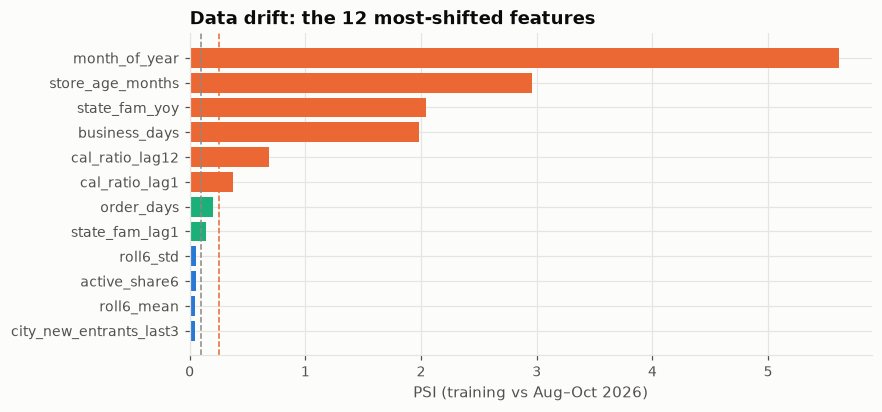

,feature,psi,ref_mean,cur_mean,status,watched,expected_by_construction
0,month_of_year,5.615,6.963,9.004,major,False,True
1,store_age_months,2.955,9.550,18.561,major,False,True
2,state_fam_yoy,2.045,0.931,0.962,major,False,True
3,business_days,1.984,21.772,21.669,major,False,True
4,cal_ratio_lag12,0.683,1.007,0.989,major,False,True
5,cal_ratio_lag1,0.376,1.021,1.001,major,False,True
6,order_days,0.202,4.358,4.337,moderate,False,True
7,state_fam_lag1,0.142,"212,912.772","212,180.668",moderate,False,False
8,roll6_std,0.052,42.932,39.078,stable,True,False
9,active_share6,0.052,0.734,0.679,stable,True,False


In [8]:
result = subprocess.run([sys.executable, str(C.ROOT / "scripts" / "04_monitor.py")],
                        capture_output=True, text=True, cwd=C.ROOT)
print("monitor ran OK" if result.returncode == 0 else result.stderr[-2000:])
monitoring = json.loads((TABLES / "monitoring.json").read_text())

drift = pd.DataFrame(monitoring["drift"])
top = drift.head(12).sort_values("psi")
colors = [P.ORANGE if v > 0.25 else P.AQUA if v > 0.10 else P.BLUE for v in top.psi]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(top.feature, top.psi, color=colors)
ax.axvline(0.10, color=P.MUTED, ls="--", lw=1); ax.axvline(0.25, color=P.ORANGE, ls="--", lw=1)
ax.set_xlabel("PSI (training vs Aug–Oct 2026)"); ax.set_title("Data drift: the 12 most-shifted features")
plt.show()
drift.head(12)

**Reading it.** Features that shift *by construction* (store age grows, calendar features change month to month)
are reported but cannot trigger retraining (`expected_by_construction`). The retrain rule watches the 10 most important
remaining features.

**A false alarm we caught.** The first version flagged `active_share6` (share of the last 6 months with orders) as a major
shift. The cause was not demand: in early 2025 the 6-month windows were not yet full. With the reference starting once
the windows are full, its PSI is 0.05 (stable). Lesson: a drift alert is a prompt to investigate, not an automatic retrain.

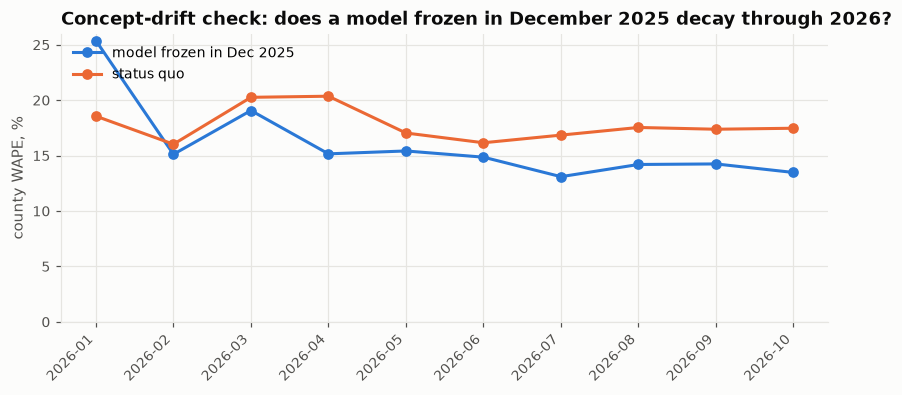

In [9]:
decay = pd.DataFrame(monitoring["stale_model_decay"])
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(decay.month, 100 * decay.stale_2025_model, marker="o", color=P.BLUE, label="model frozen in Dec 2025")
ax.plot(decay.month, 100 * decay.status_quo, marker="o", color=P.ORANGE, label="status quo")
ax.set_ylabel("county WAPE, %"); ax.set_ylim(0, None); ax.legend(loc="upper left")
ax.set_title("Concept-drift check: does a model frozen in December 2025 decay through 2026?")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
P.save(fig, "monitoring_decay"); plt.show()

**Reading it.** A model frozen in December 2025 still beats the status quo in most 2026 months, but loses badly in
**January**, the one calendar month its training data never contained. That is concept drift from an unseen season,
and the reason the deployed solution keeps a seasonal half in the ensemble and is **refitted every month**.

In [10]:
print("Schema drift (raw categories new / absent in 2026):")
display(pd.DataFrame(monitoring["schema_drift"]))
print("Retrain decision:", monitoring["retrain"])

Schema drift (raw categories new / absent in 2026):


,category_name,2025,2026,change
0,UNCLASSIFIED,0.000,"1,102.500",new in 2026
1,AMERICAN CORDIALS & LIQUEURS,"79,386.000",0.000,absent in 2026
2,AMERICAN DISTILLED SPIRITS SPECIALTY,"16,100.400",0.000,absent in 2026
3,IMPORTED CORDIALS & LIQUEURS,"176,933.200",0.000,absent in 2026
4,IMPORTED DISTILLED SPIRITS SPECIALTY,"168,232.900",0.000,absent in 2026


Retrain decision: {'retrain_now': False, 'reasons': ['no trigger fired: keep the scheduled monthly refit']}


**Retraining policy.**
1. **Scheduled:** refit every month when new data lands (production refit ~1 minute; the full pipeline ~10 minutes).
2. **Triggered:** retrain at once if a watched feature shows PSI > 0.25, if live WAPE is more than 20% worse than at
   validation, or if the model stops beating the status quo.
3. **Guardrails:** a new model is promoted only if it beats the current one *and* the status quo on the latest
   held-out month, and no group has |bias| > 5%.
4. **Data checks in the ETL:** publisher row counts, schema, truncated-month detector, unknown categories. Any failure
   stops the pipeline.

## 7. The MLOps stack

| Piece | Where | What it does |
|---|---|---|
| Reproducible pipeline | `scripts/01…05`, `notebooks/_build/build.py` | rebuilds everything from raw files |
| Experiment tracking | MLflow (`mlflow ui --backend-store-uri sqlite:///mlflow.db`) | logs every model, trial and ablation with its metrics |
| Model + model card | `models/xgb_tweedie_final.json` + `.meta.json` | features, ensemble weight, intervals, metrics |
| Serving | FastAPI `app/main.py` (+ dashboard at `/`) | `/forecast/county/{fips}`, `/forecast/store/{id}`, `/monitoring`, `/model` |
| Container | `Dockerfile` | `docker build -t abd-planner . && docker run -p 8000:8000 abd-planner` |
| Monitoring | `scripts/04_monitor.py` → `/monitoring` | PSI, monthly error, schema drift, retrain decision |

In [11]:
connection = sqlite3.connect(C.ROOT / "mlflow.db")
runs = pd.read_sql("select r.name, t.value as kind from runs r left join tags t "
                   "on r.run_uuid = t.run_uuid and t.key = 'kind'", connection)
print(f"{len(runs)} MLflow runs logged")
runs.kind.value_counts()

43 MLflow runs logged


kind
hpo                   20
baseline               4
candidate              4
candidate_ensemble     4
final_comparison       3
ablation               3
responsible_ai         2
final                  1
intervals              1
production             1
Name: count, dtype: int64